# Autoencoder Comparison

This notebook compares **LSTM-AE, CNN-LSTM-AE, and Transformer-AE** using normal-flight data. Anomaly scores are calculated from reconstruction error and evaluated using **AUROC, AUPRC, and separation ratio**.

# 1. Imports

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score
import joblib
import gc
import time

print(f"PyTorch : {torch.__version__}")
device = torch.device(
    "mps"  if torch.backends.mps.is_available()  else
    "cuda" if torch.cuda.is_available()           else
    "cpu"
)
print(f"Device  : {device}")


PyTorch : 2.11.0+cu128
Device  : cuda


# 2. Paths & config

In [16]:
PROJECT_DIR  = Path("/content/drive/MyDrive/uav-thesis/uav_px4_dataset_project")
DATA_VERSION = "v5_voltage_kfold5"
DATA_ROOT    = PROJECT_DIR / "processed_10hz" / "v4"
OUTPUT_DIR   = PROJECT_DIR / "model_outputs" / "v4" / "05_ae_comparison"
PLOT_DIR     = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = "target_energy_next_60s_wh"
ID_COLS     = ["log_id", "dataset_label", "post_gap_flag", "time_gap"]
FOLDS      = ["fold_01", "fold_02", "fold_03", "fold_04", "fold_05"]

# 3. training config

In [17]:
SEQ_LEN       = 100
STRIDE_TRAIN  = 20
STRIDE_SCORE  = 10
BATCH_SIZE    = 64
MAX_EPOCHS    = 200
PATIENCE      = 15
LR            = 1e-3
MAX_GRAD_NORM = 1.0
THRESHOLD_PCT = 95

print(f"Data root  : {DATA_ROOT}")
print(f"Output     : {OUTPUT_DIR}")
print(f"Window     : {SEQ_LEN} rows ({SEQ_LEN/10:.0f}s at 10Hz)")
print(f"Folds      : {FOLDS}")

Data root  : /content/drive/MyDrive/uav-thesis/uav_px4_dataset_project/processed_10hz/v4
Output     : /content/drive/MyDrive/uav-thesis/uav_px4_dataset_project/model_outputs/v4/05_ae_comparison
Window     : 100 rows (10s at 10Hz)
Folds      : ['fold_01', 'fold_02', 'fold_03', 'fold_04', 'fold_05']


# 4. Data loading

In [18]:
def load_fold_scaled(fold_name: str):
    """Load scaled train/val/test parquets for one fold."""
    fold_dir = DATA_ROOT / fold_name
    base     = f"no_dr_scaled_{DATA_VERSION}_{fold_name}"
    train_df = pd.read_parquet(fold_dir / f"train_{base}.parquet")
    val_df   = pd.read_parquet(fold_dir / f"val_{base}.parquet")
    test_df  = pd.read_parquet(fold_dir / f"test_{base}.parquet")
    return train_df, val_df, test_df

# quick check
_t, _v, _te = load_fold_scaled("fold_01")
feature_cols = [
    c for c in _t.columns
    if c not in ID_COLS + [TARGET_COL]
    and pd.api.types.is_numeric_dtype(_t[c])
]
N_FEATURES = len(feature_cols)
print(f"\nFold 01: train {_t.shape}  val {_v.shape}  test {_te.shape}")
print(f"Features ({N_FEATURES}): {feature_cols}")
del _t, _v, _te


Fold 01: train (602974, 21)  val (120375, 21)  test (194649, 21)
Features (16): ['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'is_idle', 'power_w_rolling_std_3s', 'voltage_per_cell', 'voltage_filtered_per_cell', 'voltage_per_cell_suspicious']


# 5. Windowing helpers

In [19]:

def prepare_sorted(df):
    """Sort by flight then time — ensures windows never cross flight boundaries."""
    df = df.copy()
    df["log_id"] = df["log_id"].astype(str)
    return df.sort_values(["log_id", "time_s"]).reset_index(drop=True)


def build_window_starts(df, seq_len, stride, normal_only=False):
    """
    Build array of window start indices, per flight.
    normal_only=True → only include flights labelled 'normal' (for training).
    """
    starts = []
    for log_id, grp in df.groupby("log_id", sort=False):
        idxs = grp.index.to_numpy()
        if len(idxs) < seq_len:
            continue
        if normal_only and grp["dataset_label"].iloc[0] != "normal":
            continue
        for offset in range(0, len(idxs) - seq_len + 1, stride):
            starts.append(idxs[offset])
    return np.array(starts, dtype=np.int64)


class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, starts, seq_len):
        self.arr, self.starts, self.seq_len = arr, starts, seq_len
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return torch.tensor(self.arr[s:s+self.seq_len], dtype=torch.float32)


class ScoringDataset(torch.utils.data.Dataset):
    """Returns (window_tensor, start_index) for score accumulation."""
    def __init__(self, arr, starts, seq_len):
        self.arr, self.starts, self.seq_len = arr, starts, seq_len
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return torch.tensor(self.arr[s:s+self.seq_len], dtype=torch.float32), s



# 6. LSTM Autoencoder

<div style="font-size: 13px; line-height: 1.5;">

**Configuration:** `hidden_size=64`, `latent_size=32`, `num_layers=2`, `dropout=0.2`

**Justification:**  
The configuration was based on Reis and Reis (2025) and Malhotra et al. (2016). Two LSTM layers were used to capture temporal patterns, while the hidden and latent sizes were kept moderate to reduce model complexity.

</div>

In [20]:

class LSTMAutoencoder(nn.Module):
    """
    LSTM Autoencoder — primary baseline architecture.

    Encoder: 2-layer LSTM → linear bottleneck (latent_size)
    Decoder: latent → initialised h0/c0 → 2-layer LSTM → output projection

    Using h0/c0 initialisation from latent (vs simple input repeat) improves
    gradient flow through the decoder and produces sharper reconstruction
    boundaries between normal and abnormal sequences.
    """
    def __init__(self, n_features, hidden_size=64, latent_size=32,
                 n_layers=2, dropout=0.2):
        super().__init__()
        self.n_layers    = n_layers
        self.hidden_size = hidden_size

        self.encoder_lstm = nn.LSTM(
            n_features, hidden_size, num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.encoder_fc   = nn.Linear(hidden_size, latent_size)

        # initialise decoder hidden and cell state from latent
        self.decoder_h0_fc  = nn.Linear(latent_size, hidden_size)
        self.decoder_c0_fc  = nn.Linear(latent_size, hidden_size)
        self.decoder_input_fc = nn.Linear(latent_size, hidden_size)

        self.decoder_lstm = nn.LSTM(
            hidden_size, hidden_size, num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.output_fc = nn.Linear(hidden_size, n_features)

    def forward(self, x):
        # encode
        _, (h, c) = self.encoder_lstm(x)
        latent    = self.encoder_fc(h[-1])          # (batch, latent)

        # initialise decoder state from latent
        h0 = self.decoder_h0_fc(latent).unsqueeze(0).repeat(self.n_layers, 1, 1)
        c0 = self.decoder_c0_fc(latent).unsqueeze(0).repeat(self.n_layers, 1, 1)

        # decode — repeat latent input across sequence
        dec_in     = self.decoder_input_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.decoder_lstm(dec_in, (h0, c0))
        return self.output_fc(dec_out)


# 7. CNN-LSTM Autoencoder

<div style="font-size: 13px; line-height: 1.5;">

**Configuration:** `cnn_channels=32`, `lstm_hidden=64`, `latent_size=32`, `kernel_size=3`, `dropout=0.2`

**Justification:**  
Two Conv1D layers extract local patterns, while the LSTM captures temporal behaviour. The configuration was based on Radaideh et al. (2022), Bai et al. (2018), and Zhang and Zhou (2023).

</div>

In [21]:

class CNNLSTMAutoencoder(nn.Module):
    """
    CNN-LSTM Autoencoder.

    Encoder: Conv1D(32, k=3) → ReLU → Conv1D(64, k=3) → ReLU
             → LSTM(64) → linear bottleneck(32)
    Decoder: latent → h0/c0 init → LSTM(64) → linear output

    The CNN layers extract local temporal patterns (e.g., short voltage spikes,
    current transients) before the LSTM captures longer-range dependencies.
    This two-stage approach is particularly suited to battery telemetry where
    both short-term signal noise and long-term discharge patterns are relevant.
    """
    def __init__(self, n_features, cnn_channels=32, lstm_hidden=64,
                 latent_size=32, kernel_size=3, dropout=0.2):
        super().__init__()

        # progressive CNN encoder: 32 → 64 channels
        self.cnn_encoder = nn.Sequential(
            nn.Conv1d(n_features, cnn_channels, kernel_size=kernel_size, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(cnn_channels, cnn_channels * 2, kernel_size=kernel_size, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.lstm_encoder   = nn.LSTM(cnn_channels * 2, lstm_hidden,
                                       batch_first=True, dropout=0.0)
        self.latent_fc      = nn.Linear(lstm_hidden, latent_size)

        self.decoder_h0_fc  = nn.Linear(latent_size, lstm_hidden)
        self.decoder_c0_fc  = nn.Linear(latent_size, lstm_hidden)
        self.decoder_input_fc = nn.Linear(latent_size, lstm_hidden)
        self.lstm_decoder   = nn.LSTM(lstm_hidden, lstm_hidden, batch_first=True)
        self.output_fc      = nn.Linear(lstm_hidden, n_features)

    def forward(self, x):
        # x: (batch, seq_len, n_features)
        # CNN expects (batch, channels, seq_len)
        cnn_out    = self.cnn_encoder(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _)  = self.lstm_encoder(cnn_out)
        latent     = self.latent_fc(h[-1])

        h0 = self.decoder_h0_fc(latent).unsqueeze(0)
        c0 = self.decoder_c0_fc(latent).unsqueeze(0)
        dec_in     = self.decoder_input_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.lstm_decoder(dec_in, (h0, c0))
        return self.output_fc(dec_out)



# 8. Transformer Autoencoder

<div style="font-size: 13px; line-height: 1.5;">

**Configuration:** `d_model=64`, `nhead=4`, `num_layers=2`, `dropout=0.1`, `dim_feedforward=256`

**Justification:**  
The architecture was scaled down for the smaller 16-feature dataset. Four attention heads divide the 64-dimensional embedding evenly, while the feedforward size follows the standard `4 × d_model` setting. A lower learning rate of `1e-4` was used for stable Transformer training.

</div>

In [22]:

class TransformerAutoencoder(nn.Module):
    """
    Transformer Autoencoder for multivariate time-series anomaly detection.

    Architecture:
        Input projection: n_features → d_model (linear)
        Positional encoding: learned parameter (seq_len × d_model)
        Encoder: num_layers × TransformerEncoderLayer(d_model, nhead)
        Output projection: d_model → n_features (linear)

    This is a reconstruction-based Transformer: the encoder reads the full
    sequence and reconstructs it. Anomaly score = per-timestep MSE, averaged
    across the window. Unlike the Anomaly Transformer (Xu et al. 2022) which
    uses association discrepancy, this implementation uses standard MSE
    reconstruction error for consistency with the LSTM-AE and CNN-LSTM-AE
    comparisons in this notebook.
    """
    def __init__(self, n_features, d_model=64, nhead=4, num_layers=2,
                 dropout=0.1, dim_feedforward=256, max_seq_len=200):
        super().__init__()
        assert d_model % nhead == 0, \
            f"d_model ({d_model}) must be divisible by nhead ({nhead})"

        self.input_proj    = nn.Linear(n_features, d_model)
        # learned positional encoding — Wang et al. (2024) ICONIP
        self.pos_encoding  = nn.Parameter(
            torch.randn(1, max_seq_len, d_model) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,   # 4 × d_model — Vaswani et al. 2017
            dropout=dropout,
            batch_first=True,
            norm_first=True    # pre-norm for stability (Wang et al. 2022)
        )
        self.transformer  = nn.TransformerEncoder(encoder_layer,
                                                   num_layers=num_layers,
                                          enable_nested_tensor=False)
        self.output_proj  = nn.Linear(d_model, n_features)

    def forward(self, x):
        seq_len = x.size(1)
        x = self.input_proj(x) + self.pos_encoding[:, :seq_len, :]
        x = self.transformer(x)
        return self.output_proj(x)


# parameter count check
_models = {
    "LSTM-AE":        LSTMAutoencoder(N_FEATURES),
    "CNN-LSTM-AE":    CNNLSTMAutoencoder(N_FEATURES),
    "Transformer-AE": TransformerAutoencoder(N_FEATURES),
}
print("\nParameter counts:")
for name, m in _models.items():
    print(f"  {name:<20}: {sum(p.numel() for p in m.parameters()):>8,}")
del _models



Parameter counts:
  LSTM-AE             :  130,288
  CNN-LSTM-AE         :   83,792
  Transformer-AE      :  114,896


# 9. Training & scoring helpers

In [23]:

def train_one_model(model, train_loader, val_loader,
                    max_epochs=MAX_EPOCHS, patience=PATIENCE,
                    lr=LR, fold_name="", model_name="",
                    save_path=None):
    """
    Train model on normal-only windows with early stopping on val loss.

    Returns
    -------
    model        : trained nn.Module with best weights restored
    best_val_loss: float
    train_losses : list
    val_losses   : list
    best_epoch   : int
    """
    model      = model.to(device)
    optimiser  = torch.optim.Adam(model.parameters(), lr=lr)
    criterion  = nn.MSELoss()
    best_val   = float("inf")
    no_improve = 0
    best_state = None
    best_epoch = 0
    train_losses, val_losses = [], []

    for epoch in range(1, max_epochs + 1):
        # ── train
        model.train()
        t_loss = 0.0
        for xb in train_loader:
            xb = xb.to(device)
            optimiser.zero_grad()
            loss = criterion(model(xb), xb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimiser.step()
            t_loss += loss.item() * len(xb)
        t_loss /= len(train_loader.dataset)

        # ── validate
        model.eval()
        v_loss = 0.0
        with torch.no_grad():
            for xb in val_loader:
                xb     = xb.to(device)
                v_loss += criterion(model(xb), xb).item() * len(xb)
        v_loss /= len(val_loader.dataset)

        train_losses.append(t_loss)
        val_losses.append(v_loss)

        if epoch % 20 == 0 or epoch == 1:
            print(f"    Epoch {epoch:3d}/{max_epochs} — "
                  f"train: {t_loss:.6f}  val: {v_loss:.6f}  "
                  f"gap: {v_loss-t_loss:+.6f}")

        if v_loss < best_val - 1e-6:
            best_val   = v_loss
            best_epoch = epoch
            no_improve = 0
            best_state = {k: v.cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"    Early stop @ epoch {epoch} "
                      f"(best val: {best_val:.6f} @ epoch {best_epoch})")
                break

    model.load_state_dict(best_state)
    model.eval()

    if save_path:
        torch.save(best_state, save_path)

    return model, best_val, train_losses, val_losses, best_epoch


def score_flights(df_sorted, X_arr, model):
    """
    Compute per-row anomaly scores by overlapping window MSE,
    then aggregate to flight level (mean score per flight).

    Returns
    -------
    row_df    : df_sorted with 'anomaly_score' column
    flight_df : one row per flight with mean_score and binary_label
    """
    starts = build_window_starts(df_sorted, SEQ_LEN, STRIDE_SCORE,
                                  normal_only=False)
    loader = torch.utils.data.DataLoader(
        ScoringDataset(X_arr, starts, SEQ_LEN),
        batch_size=256, shuffle=False
    )

    score_sum   = np.zeros(len(df_sorted), dtype=np.float64)
    score_count = np.zeros(len(df_sorted), dtype=np.float64)

    model.eval()
    with torch.no_grad():
        for xb, batch_starts in loader:
            xb    = xb.to(device)
            recon = model(xb)
            # per-timestep MSE averaged across features
            step_err = ((xb - recon) ** 2).mean(dim=2).cpu().numpy()
            for i, s in enumerate(batch_starts.numpy()):
                score_sum[s:s+SEQ_LEN]   += step_err[i]
                score_count[s:s+SEQ_LEN] += 1

    scores = np.where(score_count > 0, score_sum / score_count, np.nan)

    row_df = df_sorted.copy()
    row_df["anomaly_score"] = scores

    # fill short-flight rows that weren't covered by any window
    if row_df["anomaly_score"].isna().any():
        row_df["anomaly_score"] = (
            row_df.groupby("log_id")["anomaly_score"]
            .transform(lambda s: s.ffill().bfill())
        )
    fallback = row_df.loc[
        row_df["dataset_label"] == "normal", "anomaly_score"
    ].median()
    row_df["anomaly_score"] = row_df["anomaly_score"].fillna(fallback)

    # flight-level aggregation
    flight_df = (
        row_df.groupby(["log_id", "dataset_label"])["anomaly_score"]
        .mean().reset_index()
        .rename(columns={"anomaly_score": "mean_score"})
    )
    flight_df["binary_label"] = (
        flight_df["dataset_label"] == "abnormal"
    ).astype(int)

    return row_df, flight_df


def compute_metrics(flight_df):
    """Compute AUROC, AUPRC, and separation ratio from flight-level scores."""
    if flight_df["binary_label"].nunique() < 2:
        return {"auroc": np.nan, "auprc": np.nan, "sep_ratio": np.nan}

    auroc = roc_auc_score(flight_df["binary_label"], flight_df["mean_score"])
    auprc = average_precision_score(flight_df["binary_label"],
                                    flight_df["mean_score"])
    n_mean = flight_df.loc[flight_df["binary_label"]==0, "mean_score"].mean()
    a_mean = flight_df.loc[flight_df["binary_label"]==1, "mean_score"].mean()
    sep    = a_mean / n_mean if n_mean > 0 else np.nan

    return {
        "auroc":     round(float(auroc), 4),
        "auprc":     round(float(auprc), 4),
        "sep_ratio": round(float(sep),   4),
    }


def plot_loss_curves(train_l, val_l, fold_name, model_name):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(train_l, color="steelblue", label="Train")
    ax.plot(val_l,   color="tomato",    label="Val")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.set_title(f"Loss — {model_name} | {fold_name}")
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = model_name.lower().replace("-","_").replace(" ","_")
    plt.savefig(PLOT_DIR / f"loss_{safe}_{fold_name}.png", dpi=150)
    plt.close()


def plot_score_dist(train_normal_scores, flight_df, threshold,
                    fold_name, model_name):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(train_normal_scores, bins=80, alpha=0.5, density=True,
            color="steelblue", label="Train normal scores")
    nrm = flight_df[flight_df["dataset_label"]=="normal"]["mean_score"].values
    abn = flight_df[flight_df["dataset_label"]=="abnormal"]["mean_score"].values
    if len(nrm): ax.hist(nrm, bins=40, alpha=0.5, density=True,
                          color="green", label="Test normal")
    if len(abn): ax.hist(abn, bins=40, alpha=0.5, density=True,
                          color="red", label="Test abnormal")
    ax.axvline(threshold, color="black", linestyle="--", linewidth=1.5,
               label=f"Threshold (p{THRESHOLD_PCT})")
    ax.set_xlabel("Reconstruction MSE"); ax.set_ylabel("Density")
    ax.set_title(f"Score distributions — {model_name} | {fold_name}")
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = model_name.lower().replace("-","_").replace(" ","_")
    plt.savefig(PLOT_DIR / f"scores_{safe}_{fold_name}.png", dpi=150)
    plt.close()

# 10. Architecture configs

<div style="font-size: 13px; line-height: 1.5;">

**Model configuration:**  
Each configuration is passed to the model using `**kwargs`. The Transformer uses a learning rate of `1e-4`, while LSTM-AE and CNN-LSTM-AE use `1e-3`.

</div>

In [24]:

ARCHITECTURES = {
    "LSTM-AE": {
        "class"  : LSTMAutoencoder,
        "kwargs" : dict(hidden_size=64, latent_size=32, n_layers=2, dropout=0.2),
        "lr"     : 1e-3,
        # Reis & Reis (2025) Sensors 25(16) 4944 — PX4 UAV baseline
        # Malhotra et al. (2016) arXiv:1607.00148 — LSTM encoder-decoder AE
    },
    "CNN-LSTM-AE": {
        "class"  : CNNLSTMAutoencoder,
        "kwargs" : dict(cnn_channels=32, lstm_hidden=64, latent_size=32,
                        kernel_size=3, dropout=0.2),
        "lr"     : 1e-3,
        # Radaideh et al. (2022) IEEE — ConvLSTM-AE sensor anomaly, AUC 0.90
        # Zhang & Zhou (2023) Struct. Control Health Monit. — CNN-LSTM structural
        # Bai et al. (2018) arXiv:1803.01271 — kernel_size=3 standard for Conv1D
    },
    "Transformer-AE": {
        "class"  : TransformerAutoencoder,
        "kwargs" : dict(d_model=64, nhead=4, num_layers=2,
                        dropout=0.1, dim_feedforward=256),
        "lr"     : 1e-4,
        # Xu et al. (2022) ICLR — Anomaly Transformer (d_model=512, nhead=8
        # scaled down to d_model=64, nhead=4 for 16-feature small dataset)
        # Vaswani et al. (2017) NeurIPS — dim_feedforward = 4 × d_model
        # lr=1e-4 directly from Xu et al. (2022)
    },
}

# 11. Main 5-fold loop

In [25]:

all_results = []

for fold_name in FOLDS:
    print(f"\n{'='*70}")
    print(f"FOLD: {fold_name}")
    print(f"{'='*70}")

    # load data
    train_df, val_df, test_df = load_fold_scaled(fold_name)

    feature_cols = [
        c for c in train_df.columns
        if c not in ID_COLS + [TARGET_COL]
        and pd.api.types.is_numeric_dtype(train_df[c])
    ]

    # sort by flight then time
    train_s = prepare_sorted(train_df)
    val_s   = prepare_sorted(val_df)
    test_s  = prepare_sorted(test_df)

    X_train = train_s[feature_cols].to_numpy(dtype=np.float32)
    X_val   = val_s[feature_cols].to_numpy(dtype=np.float32)
    X_test  = test_s[feature_cols].to_numpy(dtype=np.float32)

    # NaN check
    for name, arr in [("Train", X_train), ("Val", X_val), ("Test", X_test)]:
        assert not np.isnan(arr).any(), f"{fold_name} | {name}: NaNs in features"
    print("NaN check ✓")

    # build windows — normal only for train/val
    train_starts = build_window_starts(train_s, SEQ_LEN, STRIDE_TRAIN,
                                        normal_only=True)
    val_starts   = build_window_starts(val_s,   SEQ_LEN, STRIDE_TRAIN,
                                        normal_only=True)
    print(f"Train windows: {len(train_starts):,}  |  Val windows: {len(val_starts):,}")

    train_loader = torch.utils.data.DataLoader(
        WindowDataset(X_train, train_starts, SEQ_LEN),
        batch_size=BATCH_SIZE, shuffle=True,  num_workers=0
    )
    val_loader = torch.utils.data.DataLoader(
        WindowDataset(X_val, val_starts, SEQ_LEN),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )

    for arch_name, cfg in ARCHITECTURES.items():
        print(f"\n  ── {arch_name} ──────────────────────────────────────")

        model = cfg["class"](N_FEATURES, **cfg["kwargs"])
        n_params = sum(p.numel() for p in model.parameters())
        print(f"  Parameters: {n_params:,}")

        save_path = OUTPUT_DIR / \
            f"{arch_name.lower().replace('-','_')}_{fold_name}.pt"

        t0 = time.time()
        model, best_val, tr_l, vl_l, best_ep = train_one_model(
            model, train_loader, val_loader,
            lr=cfg["lr"],
            fold_name=fold_name, model_name=arch_name,
            save_path=save_path
        )
        elapsed = time.time() - t0

        # plot loss curves
        plot_loss_curves(tr_l, vl_l, fold_name, arch_name)

        # threshold from 95th pct of normal training row scores
        _, train_flight_df = score_flights(train_s, X_train, model)
        train_normal_scores = train_flight_df.loc[
            train_flight_df["dataset_label"] == "normal", "mean_score"
        ].values
        threshold = float(np.percentile(train_normal_scores, THRESHOLD_PCT))
        print(f"  Threshold (p{THRESHOLD_PCT}): {threshold:.6f}")

        # score test set
        _, test_flight_df = score_flights(test_s, X_test, model)
        test_metrics = compute_metrics(test_flight_df)

        # score val set
        _, val_flight_df = score_flights(val_s, X_val, model)
        val_metrics = compute_metrics(val_flight_df)

        # plot score distributions
        plot_score_dist(train_normal_scores, test_flight_df,
                        threshold, fold_name, arch_name)

        print(f"\n  RESULTS — {arch_name} | {fold_name}")
        print(f"    Val  AUROC : {val_metrics['auroc']:.4f}  "
              f"AUPRC: {val_metrics['auprc']:.4f}  "
              f"Sep: {val_metrics['sep_ratio']:.2f}×")
        print(f"    Test AUROC : {test_metrics['auroc']:.4f}  "
              f"AUPRC: {test_metrics['auprc']:.4f}  "
              f"Sep: {test_metrics['sep_ratio']:.2f}×")
        print(f"    Best epoch : {best_ep}  |  Time: {elapsed:.0f}s")

        # save flight scores for downstream anomaly-aware regression
        test_flight_df["fold"]      = fold_name
        test_flight_df["model"]     = arch_name
        test_flight_df["threshold"] = threshold
        safe = arch_name.lower().replace("-","_")
        test_flight_df.to_parquet(
            OUTPUT_DIR / f"flight_scores_{safe}_{fold_name}.parquet",
            index=False
        )

        all_results.append({
            "fold"              : fold_name,
            "architecture"      : arch_name,
            "val_auroc"         : val_metrics["auroc"],
            "val_auprc"         : val_metrics["auprc"],
            "val_sep_ratio"     : val_metrics["sep_ratio"],
            "test_auroc"        : test_metrics["auroc"],
            "test_auprc"        : test_metrics["auprc"],
            "test_sep_ratio"    : test_metrics["sep_ratio"],
            "threshold"         : round(threshold, 6),
            "best_val_loss"     : round(best_val, 6),
            "best_epoch"        : best_ep,
            "training_seconds"  : round(elapsed, 1),
            "n_params"          : n_params,
        })

        # free memory before next model
        del model
        gc.collect()
        if device.type == "mps":  torch.mps.empty_cache()
        if device.type == "cuda": torch.cuda.empty_cache()

    print(f"\n{fold_name} complete ✓")

print(f"\n{'='*70}")
print("ALL 5 FOLDS × 3 ARCHITECTURES COMPLETE")
print(f"{'='*70}")


FOLD: fold_01
NaN check ✓
Train windows: 22,831  |  Val windows: 4,512

  ── LSTM-AE ──────────────────────────────────────
  Parameters: 130,288
    Epoch   1/200 — train: 0.343027  val: 0.201816  gap: -0.141211
    Epoch  20/200 — train: 0.117786  val: 0.104342  gap: -0.013443
    Epoch  40/200 — train: 0.093572  val: 0.062137  gap: -0.031435
    Epoch  60/200 — train: 0.076231  val: 0.044754  gap: -0.031478
    Epoch  80/200 — train: 0.063945  val: 0.038188  gap: -0.025757
    Epoch 100/200 — train: 0.058665  val: 0.035147  gap: -0.023518
    Epoch 120/200 — train: 0.049058  val: 0.030414  gap: -0.018644
    Epoch 140/200 — train: 0.046577  val: 0.029846  gap: -0.016732
    Epoch 160/200 — train: 0.042679  val: 0.029064  gap: -0.013615
    Epoch 180/200 — train: 0.038347  val: 0.024487  gap: -0.013860
    Epoch 200/200 — train: 0.038100  val: 0.023043  gap: -0.015057


/tmp/ipykernel_4955/882682286.py:109: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)


  Threshold (p95): 0.148430


/tmp/ipykernel_4955/882682286.py:109: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/tmp/ipykernel_4955/882682286.py:109: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)



  RESULTS — LSTM-AE | fold_01
    Val  AUROC : 0.4844  AUPRC: 0.3219  Sep: 1.37×
    Test AUROC : 0.5330  AUPRC: 0.3465  Sep: 3.11×
    Best epoch : 200  |  Time: 469s

  ── CNN-LSTM-AE ──────────────────────────────────────
  Parameters: 83,792
    Epoch   1/200 — train: 0.296945  val: 0.182348  gap: -0.114597
    Epoch  20/200 — train: 0.115783  val: 0.094121  gap: -0.021662
    Epoch  40/200 — train: 0.091777  val: 0.057713  gap: -0.034064
    Epoch  60/200 — train: 0.077430  val: 0.050603  gap: -0.026827
    Epoch  80/200 — train: 0.070101  val: 0.051055  gap: -0.019046
    Epoch 100/200 — train: 0.064168  val: 0.045002  gap: -0.019166
    Epoch 120/200 — train: 0.059280  val: 0.042126  gap: -0.017154
    Epoch 140/200 — train: 0.056485  val: 0.040155  gap: -0.016330
    Epoch 160/200 — train: 0.076704  val: 0.049974  gap: -0.026731
    Early stop @ epoch 163 (best val: 0.036123 @ epoch 148)


...


  RESULTS — CNN-LSTM-AE | fold_05
    Val  AUROC : 0.7812  AUPRC: 0.8056  Sep: 20.28×
    Test AUROC : 0.6571  AUPRC: 0.3542  Sep: 2.03×
    Best epoch : 32  |  Time: 110s

  ── Transformer-AE ──────────────────────────────────────
  Parameters: 114,896
    Epoch   1/200 — train: 0.193708  val: 0.030002  gap: -0.163706
    Epoch  20/200 — train: 0.000416  val: 0.000407  gap: -0.000009
    Epoch  40/200 — train: 0.000023  val: 0.000172  gap: +0.000149
    Epoch  60/200 — train: 0.000006  val: 0.000126  gap: +0.000119
    Epoch  80/200 — train: 0.000003  val: 0.000082  gap: +0.000079
    Epoch 100/200 — train: 0.000002  val: 0.000049  gap: +0.000047
    Epoch 120/200 — train: 0.000002  val: 0.000035  gap: +0.000033
    Epoch 140/200 — train: 0.000001  val: 0.000028  gap: +0.000027
    Early stop @ epoch 151 (best val: 0.000029 @ epoch 136)


/tmp/ipykernel_4955/882682286.py:109: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)


  Threshold (p95): 0.000001


/tmp/ipykernel_4955/882682286.py:109: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/tmp/ipykernel_4955/882682286.py:109: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)



  RESULTS — Transformer-AE | fold_05
    Val  AUROC : 0.7969  AUPRC: 0.8088  Sep: 45.84×
    Test AUROC : 0.7029  AUPRC: 0.4470  Sep: 6.78×
    Best epoch : 136  |  Time: 419s

fold_05 complete ✓

ALL 5 FOLDS × 3 ARCHITECTURES COMPLETE


# 12. Summary

In [26]:

results_df = pd.DataFrame(all_results)
results_df.to_csv(OUTPUT_DIR / "ae_comparison_all_folds.csv", index=False)

print("\n5-FOLD MEAN ± STD BY ARCHITECTURE")
print("="*70)

summary = (
    results_df
    .groupby("architecture")[
        ["test_auroc", "test_auprc", "test_sep_ratio",
         "best_epoch", "training_seconds", "n_params"]
    ]
    .agg(["mean", "std"])
    .round(4)
)
print(summary.to_string())
summary.to_csv(OUTPUT_DIR / "ae_comparison_5fold_summary.csv")

# flat readable summary sorted by AUROC
flat = []
for arch in results_df["architecture"].unique():
    sub = results_df[results_df["architecture"] == arch]
    flat.append({
        "architecture"       : arch,
        "AUROC mean"         : round(sub["test_auroc"].mean(), 4),
        "AUROC std"          : round(sub["test_auroc"].std(),  4),
        "AUPRC mean"         : round(sub["test_auprc"].mean(), 4),
        "Sep ratio mean"     : round(sub["test_sep_ratio"].mean(), 2),
        "Sep ratio median"   : round(sub["test_sep_ratio"].median(), 2),
        "Best epoch mean"    : round(sub["best_epoch"].mean(), 1),
        "Training time (s)"  : round(sub["training_seconds"].mean(), 0),
        "n_params"           : int(sub["n_params"].iloc[0]),
    })

flat_df = (pd.DataFrame(flat)
           .sort_values("AUROC mean", ascending=False)
           .reset_index(drop=True))
flat_df.index += 1
print("\n--- FLAT SUMMARY (sorted by AUROC) ---")
print(flat_df.to_string())
flat_df.to_csv(OUTPUT_DIR / "ae_comparison_flat_summary.csv", index=False)

winner = flat_df.iloc[0]["architecture"]
print(f"\n✓ Best architecture: {winner}")
print(f"  AUROC: {flat_df.iloc[0]['AUROC mean']:.4f} ± "
      f"{flat_df.iloc[0]['AUROC std']:.4f}")


5-FOLD MEAN ± STD BY ARCHITECTURE
               test_auroc         test_auprc         test_sep_ratio          best_epoch          training_seconds            n_params     
                     mean     std       mean     std           mean      std       mean      std             mean       std      mean  std
architecture                                                                                                                              
CNN-LSTM-AE        0.5507  0.0782     0.4013  0.0788         3.1607   1.3122       92.6  53.2945            255.5  128.6467   83792.0  0.0
LSTM-AE            0.5660  0.0747     0.4167  0.1108         3.7140   1.0138      153.4  60.7026            399.7  137.0567  130288.0  0.0
Transformer-AE     0.6811  0.0778     0.5589  0.1221        78.5753  81.1802       88.8  31.9640            290.7   86.4430  114896.0  0.0

--- FLAT SUMMARY (sorted by AUROC) ---
     architecture  AUROC mean  AUROC std  AUPRC mean  Sep ratio mean  Sep ratio median  Bes

# 13.  Comparison plot

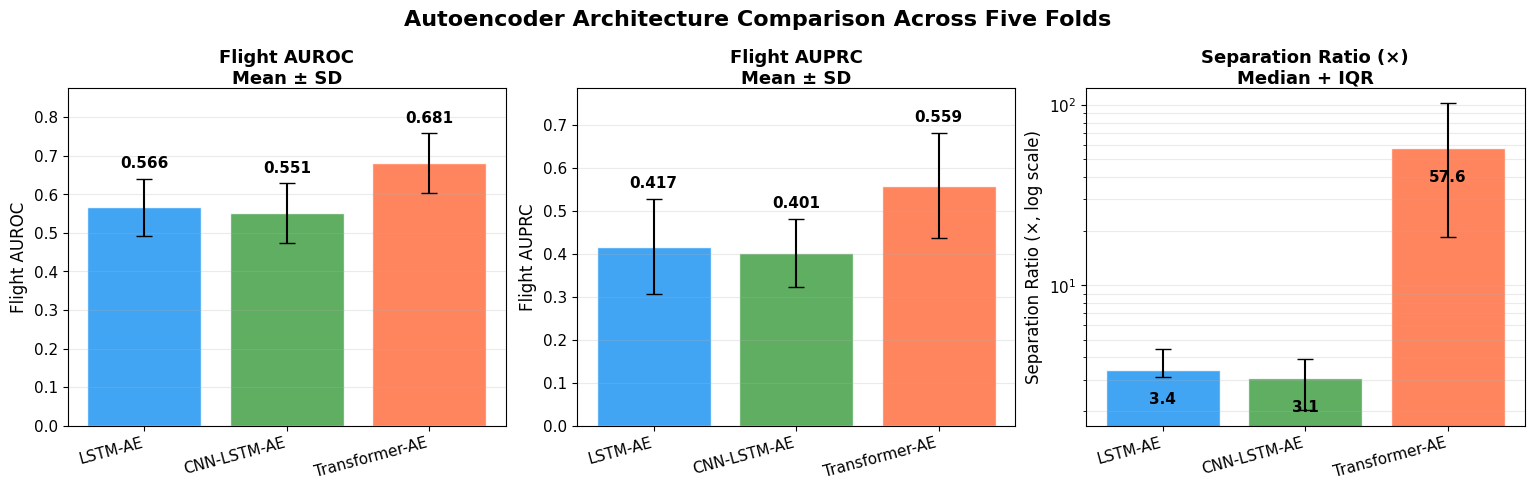

In [27]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15.5, 5.2)
)

fig.suptitle(
    "Autoencoder Architecture Comparison Across Five Folds",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

colors = ["#2196F3", "#43A047", "#FF7043"]
archs = ["LSTM-AE", "CNN-LSTM-AE", "Transformer-AE"]

# AUROC and AUPRC: mean ± standard deviation

metrics = [
    ("test_auroc", "Flight AUROC"),
    ("test_auprc", "Flight AUPRC")
]

for ax, (metric, ylabel) in zip(axes[:2], metrics):

    for i, arch in enumerate(archs):

        values = results_df.loc[
            results_df["architecture"] == arch,
            metric
        ]

        mean = values.mean()
        std = values.std()

        ax.bar(
            i,
            mean,
            yerr=std,
            color=colors[i],
            alpha=0.85,
            capsize=6,
            edgecolor="white",
            linewidth=1
        )

        ax.text(
            i,
            mean + std + 0.02,
            f"{mean:.3f}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )

    ax.set_title(
        f"{ylabel}\nMean ± SD",
        fontsize=13,
        fontweight="bold",
        pad=3
    )

    ax.set_ylabel(
        ylabel,
        fontsize=12
    )

    ax.set_xticks(range(len(archs)))

    ax.set_xticklabels(
        archs,
        rotation=15,
        ha="right",
        fontsize=11
    )

    ax.tick_params(
        axis="y",
        labelsize=11
    )

    ax.grid(
        True,
        alpha=0.25,
        axis="y"
    )

    # Small amount of headroom for value labels
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.10)



# Separation ratio: median + IQR on log scale

ax = axes[2]

for i, arch in enumerate(archs):

    values = results_df.loc[
        results_df["architecture"] == arch,
        "test_sep_ratio"
    ].values

    median = np.median(values)
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)

    lower_error = median - q1
    upper_error = q3 - median

    ax.bar(
        i,
        median,
        yerr=np.array([[lower_error], [upper_error]]),
        color=colors[i],
        alpha=0.85,
        capsize=6,
        edgecolor="white",
        linewidth=1
    )

    # Place median value inside the bar
    ax.text(
        i,
        median / 1.45,
        f"{median:.1f}",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

ax.set_yscale("log")

ax.set_title(
    "Separation Ratio (×)\nMedian + IQR",
    fontsize=13,
    fontweight="bold",
    pad=3
)

ax.set_ylabel(
    "Separation Ratio (×, log scale)",
    fontsize=12
)

ax.set_xticks(range(len(archs)))

ax.set_xticklabels(
    archs,
    rotation=15,
    ha="right",
    fontsize=11
)

ax.tick_params(
    axis="y",
    labelsize=11
)

ax.grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)



fig.subplots_adjust(
    left=0.055,
    right=0.995,
    bottom=0.18,
    top=0.83,
    wspace=0.16
)

plt.savefig(
    PLOT_DIR / "architecture_comparison_thesis.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02
)

plt.show()
plt.close()